In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
RANDOM_STATE = 42
DATA_PATH = "electric_vehicles_spec_2025.csv.csv"
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (478, 22)


,brand,model,top_speed_kmh,battery_capacity_kWh,battery_type,number_of_cells,torque_nm,efficiency_wh_per_km,range_km,acceleration_0_100_s,...,towing_capacity_kg,cargo_volume_l,seats,drivetrain,segment,length_mm,width_mm,height_mm,car_body_type,source_url
0,Abarth,500e Convertible,155,37.8,Lithium-ion,192.0,235.0,156,225,7.0,...,0.0,185,4,FWD,B - Compact,3673,1683,1518,Hatchback,https://ev-database.org/car/1904/Abarth-500e-C...
1,Abarth,500e Hatchback,155,37.8,Lithium-ion,192.0,235.0,149,225,7.0,...,0.0,185,4,FWD,B - Compact,3673,1683,1518,Hatchback,https://ev-database.org/car/1903/Abarth-500e-H...
2,Abarth,600e Scorpionissima,200,50.8,Lithium-ion,102.0,345.0,158,280,5.9,...,0.0,360,5,FWD,JB - Compact,4187,1779,1557,SUV,https://ev-database.org/car/3057/Abarth-600e-S...
3,Abarth,600e Turismo,200,50.8,Lithium-ion,102.0,345.0,158,280,6.2,...,0.0,360,5,FWD,JB - Compact,4187,1779,1557,SUV,https://ev-database.org/car/3056/Abarth-600e-T...
4,Aiways,U5,150,60.0,Lithium-ion,NaN,310.0,156,315,7.5,...,NaN,496,5,FWD,JC - Medium,4680,1865,1700,SUV,https://ev-database.org/car/1678/Aiways-U5


In [11]:
print("Column data types:")
print(df.dtypes)
print("\nMissing values in each column:")
print(df.isnull().sum().sort_values(ascending=False))
print("\nDuplicated rows:", df.duplicated().sum())
print("\nTarget class distribution:")
print(df["drivetrain"].value_counts())
print("\nNumerical summary:")
display(df.describe())

Column data types:
brand                         object
model                         object
top_speed_kmh                  int64
battery_capacity_kWh         float64
battery_type                  object
number_of_cells              float64
torque_nm                    float64
efficiency_wh_per_km           int64
range_km                       int64
acceleration_0_100_s         float64
fast_charging_power_kw_dc    float64
fast_charge_port              object
towing_capacity_kg           float64
cargo_volume_l                object
seats                          int64
drivetrain                    object
segment                       object
length_mm                      int64
width_mm                       int64
height_mm                      int64
car_body_type                 object
source_url                    object
dtype: object

Missing values in each column:
number_of_cells              202
towing_capacity_kg            26
torque_nm                      7
fast_charge_port      

,top_speed_kmh,battery_capacity_kWh,number_of_cells,torque_nm,efficiency_wh_per_km,range_km,acceleration_0_100_s,fast_charging_power_kw_dc,towing_capacity_kg,seats,length_mm,width_mm,height_mm
count,478.000000,478.000000,276.000000,471.000000,478.000000,478.000000,478.000000,477.000000,452.000000,478.000000,478.000000,478.000000,478.000000
mean,185.487448,74.043724,485.293478,498.012739,162.903766,393.179916,6.882636,125.008386,1052.261062,5.263598,4678.506276,1887.359833,1601.125523
std,34.252773,20.331058,1210.819733,241.461128,34.317532,103.287335,2.730696,58.205012,737.851774,1.003961,369.210573,73.656807,130.754851
min,125.000000,21.300000,72.000000,113.000000,109.000000,135.000000,2.200000,29.000000,0.000000,2.000000,3620.000000,1610.000000,1329.000000
25%,160.000000,60.000000,150.000000,305.000000,143.000000,320.000000,4.800000,80.000000,500.000000,5.000000,4440.000000,1849.000000,1514.000000
50%,180.000000,76.150000,216.000000,430.000000,155.000000,397.500000,6.600000,113.000000,1000.000000,5.000000,4720.000000,1890.000000,1596.000000
75%,201.000000,90.600000,324.000000,679.000000,177.750000,470.000000,8.200000,150.000000,1600.000000,5.000000,4961.000000,1939.000000,1665.000000
max,325.000000,118.000000,7920.000000,1350.000000,370.000000,685.000000,19.100000,281.000000,2500.000000,9.000000,5908.000000,2080.000000,1986.000000


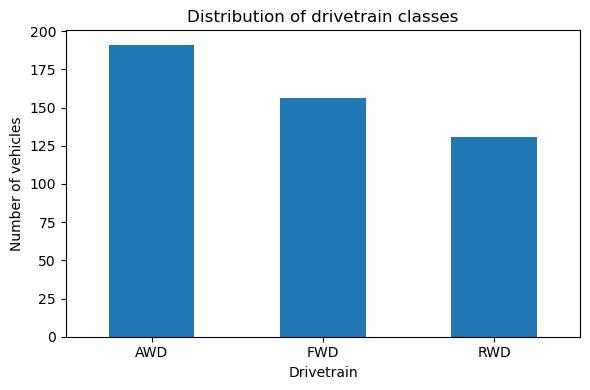

In [12]:
plt.figure(figsize=(6, 4))
df["drivetrain"].value_counts().sort_index().plot(kind="bar")
plt.title("Distribution of drivetrain classes")
plt.xlabel("Drivetrain")
plt.ylabel("Number of vehicles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [13]:
print("Rows before removing exact duplicates:", len(df))
df = df.drop_duplicates().copy()
print("Rows after removing exact duplicates:", len(df))
invalid_cargo = df["cargo_volume_l"].notna() & pd.to_numeric(
    df["cargo_volume_l"], errors="coerce"
).isna()
print("\nNon-numeric cargo volume entries:", int(invalid_cargo.sum()))
print(df.loc[invalid_cargo, "cargo_volume_l"].value_counts())
df["cargo_volume_l"] = pd.to_numeric(df["cargo_volume_l"], errors="coerce")
print("Cargo volume data type after conversion:", df["cargo_volume_l"].dtype)
print("Missing cargo volume values after conversion:", df["cargo_volume_l"].isna().sum())

Rows before removing exact duplicates: 478
Rows after removing exact duplicates: 478

Non-numeric cargo volume entries: 3
cargo_volume_l
10 Banana Boxes    1
31 Banana Boxes    1
13 Banana Boxes    1
Name: count, dtype: int64
Cargo volume data type after conversion: float64
Missing cargo volume values after conversion: 4


In [14]:
missing_percent = (df.isna().mean() * 100).sort_values(ascending=False)
print("Missing percentage by column:")
print(missing_percent.round(2))
constant_columns = df.columns[df.nunique(dropna=False) <= 1].tolist()
print("\nConstant columns:", constant_columns)
columns_to_drop = [
    "brand", "model", "source_url", "segment", "car_body_type",
    "battery_type", "number_of_cells"
]

X = df.drop(columns=columns_to_drop + ["drivetrain"])
y = df["drivetrain"]

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("\nSelected numeric features:", numeric_features)
print("Selected categorical features:", categorical_features)
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Missing percentage by column:
number_of_cells              42.26
towing_capacity_kg            5.44
torque_nm                     1.46
cargo_volume_l                0.84
fast_charge_port              0.21
fast_charging_power_kw_dc     0.21
model                         0.21
seats                         0.00
car_body_type                 0.00
height_mm                     0.00
width_mm                      0.00
length_mm                     0.00
segment                       0.00
drivetrain                    0.00
brand                         0.00
acceleration_0_100_s          0.00
range_km                      0.00
efficiency_wh_per_km          0.00
battery_type                  0.00
battery_capacity_kWh          0.00
top_speed_kmh                 0.00
source_url                    0.00
dtype: float64

Constant columns: ['battery_type']

Selected numeric features: ['top_speed_kmh', 'battery_capacity_kWh', 'torque_nm', 'efficiency_wh_per_km', 'range_km', 'acceleration_0_100_s', 'fast_

In [15]:
numeric_transformer = SimpleImputer(strategy="median", add_indicator=True)

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("\nTraining class counts:")
print(y_train.value_counts())
print("\nTesting class counts:")
print(y_test.value_counts())
print("\nMissing feature values before imputation (train):", int(X_train.isna().sum().sum()))

Training data: (382, 14)
Testing data: (96, 14)

Training class counts:
drivetrain
AWD    152
FWD    125
RWD    105
Name: count, dtype: int64

Testing class counts:
drivetrain
AWD    39
FWD    31
RWD    26
Name: count, dtype: int64

Missing feature values before imputation (train): 27


In [17]:
model = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=250,
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")
print("Five-fold training cross-validation accuracy:", np.round(cv_scores, 3))
print(f"Mean CV accuracy: {cv_scores.mean():.2%} (+/- {cv_scores.std():.2%})")
model.fit(X_train, y_train)
print("\nModel trained successfully.")

Five-fold training cross-validation accuracy: [0.961 0.935 0.974 0.895 0.987]
Mean CV accuracy: 95.03% (+/- 3.26%)

Model trained successfully.


In [18]:
processed_train = model.named_steps["preprocess"].transform(X_train)
processed_test = model.named_steps["preprocess"].transform(X_test)
if hasattr(processed_train, "toarray"):
    processed_train = processed_train.toarray()
if hasattr(processed_test, "toarray"):
    processed_test = processed_test.toarray()
print("Training features after preprocessing:", processed_train.shape)
print("Missing values after preprocessing (train):", int(pd.isna(processed_train).sum()))
print("Missing values after preprocessing (test):", int(pd.isna(processed_test).sum()))

Training features after preprocessing: (382, 19)
Missing values after preprocessing (train): 0
Missing values after preprocessing (test): 0


In [19]:
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
majority_baseline = y_test.value_counts(normalize=True).max()

print(f"Accuracy score: {accuracy:.4f} ({accuracy:.2%})")
print(f"Majority-class baseline: {majority_baseline:.2%}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, digits=3, zero_division=0))

report = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
print("Macro-average F1-score:", round(report["macro avg"]["f1-score"], 3))

Accuracy score: 0.9167 (91.67%)
Majority-class baseline: 40.62%

Classification Report:
              precision    recall  f1-score   support

         AWD      0.929     1.000     0.963        39
         FWD      0.933     0.903     0.918        31
         RWD      0.875     0.808     0.840        26

    accuracy                          0.917        96
   macro avg      0.912     0.904     0.907        96
weighted avg      0.916     0.917     0.915        96

Macro-average F1-score: 0.907


Confusion matrix (rows = actual, columns = predicted):


,AWD,FWD,RWD
AWD,39,0,0
FWD,0,28,3
RWD,3,2,21


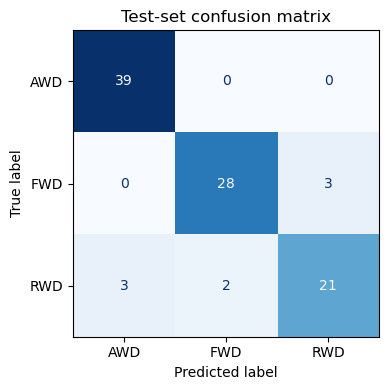

In [20]:
labels = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)
print("Confusion matrix (rows = actual, columns = predicted):")
display(pd.DataFrame(cm, index=labels, columns=labels))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels).plot(
    ax=ax, cmap="Blues", colorbar=False
)
ax.set_title("Test-set confusion matrix")
plt.tight_layout()
plt.show()